In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\ranen\OneDrive\Desktop\datasets\retail.csv")

In [3]:
df.head()

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
0,ORD100674,2024-07-20,Diya Verma,34.0,m,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,0.0,4.0,Net Banking,4.0,0.0,NaN,NaN
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,M,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,40.0,2.0,Debit Card,NaN,0.0,NEWUSER15,NaN
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,10.0,3.0,Credit Card,4.0,NaN,FEST20,NaN
3,ORD100802,2024-04-14,Riya Kapoor,49.0,NaN,Nagpur,Apparel,Men Cotton T-Shirt,1.0,1246.09,0.0,2.0,NaN,NaN,NaN,NEWUSER15,NaN
4,ORD101208,2023-09-17,Sneha Pillai,39.0,M,Lucknow,Grocery,Green Tea Pack,1.0,379.31,25.0,4.0,Debit Card,NaN,80.0,FLAT100,NaN


# Initial Inspection

In [4]:
df.shape

(3060, 17)

In [5]:
df.columns

Index(['OrderID', 'OrderDate', 'CustomerName', 'CustomerAge', 'Gender',
       'CustomerCity', 'ProductCategory', 'ProductName', 'Quantity',
       'UnitPrice', 'DiscountPercent', 'DeliveryDays', 'PaymentMethod',
       'CustomerRating', 'ShippingCost', 'CouponCode', 'ReturnReason'],
      dtype='object')

In [6]:
df.describe()

,CustomerAge,Quantity,UnitPrice,DiscountPercent,DeliveryDays,CustomerRating,ShippingCost
count,2969.000000,3060.000000,2982.000000,3060.000000,3060.000000,2200.000000,1992.000000
mean,34.638599,2.838235,999.326486,12.970588,5.846405,3.842273,52.259036
std,12.028286,10.545763,1037.875697,12.757929,4.674701,1.163776,46.463232
min,0.000000,-5.000000,80.350000,-25.000000,-3.000000,1.000000,0.000000
25%,28.000000,1.000000,478.497500,5.000000,4.000000,3.000000,0.000000
50%,34.000000,2.000000,785.930000,10.000000,5.000000,4.000000,60.000000
75%,41.000000,3.000000,1331.112500,20.000000,8.000000,5.000000,80.000000
max,150.000000,200.000000,20819.867889,150.000000,60.000000,5.000000,150.000000


In [7]:
df.dtypes

OrderID             object
OrderDate           object
CustomerName        object
CustomerAge        float64
Gender              object
CustomerCity        object
ProductCategory     object
ProductName         object
Quantity           float64
UnitPrice          float64
DiscountPercent    float64
DeliveryDays       float64
PaymentMethod       object
CustomerRating     float64
ShippingCost       float64
CouponCode          object
ReturnReason        object
dtype: object

- Insights of dataset from above description :-
- Data Type of OrderDate column should be coverted into date datatype
- Customer Age columns data type must be int
- Quantity columns data type must be int
- Quantity has a minimum of -5 (quantity cannot be negative)
- DiscountPercentage has minimum of -25 and max of 150 which is invalid
- CustomerAge also has same problem of max and min values (invalid values)
- Missing values are present in few columns 

In [8]:
# Understanding text columns 

In [9]:
df.head()

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
0,ORD100674,2024-07-20,Diya Verma,34.0,m,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,0.0,4.0,Net Banking,4.0,0.0,NaN,NaN
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,M,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,40.0,2.0,Debit Card,NaN,0.0,NEWUSER15,NaN
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,10.0,3.0,Credit Card,4.0,NaN,FEST20,NaN
3,ORD100802,2024-04-14,Riya Kapoor,49.0,NaN,Nagpur,Apparel,Men Cotton T-Shirt,1.0,1246.09,0.0,2.0,NaN,NaN,NaN,NEWUSER15,NaN
4,ORD101208,2023-09-17,Sneha Pillai,39.0,M,Lucknow,Grocery,Green Tea Pack,1.0,379.31,25.0,4.0,Debit Card,NaN,80.0,FLAT100,NaN


In [10]:
df.select_dtypes(object)

,OrderID,OrderDate,CustomerName,Gender,CustomerCity,ProductCategory,ProductName,PaymentMethod,CouponCode,ReturnReason
0,ORD100674,2024-07-20,Diya Verma,m,Delhi,Beauty & Personal Care,Lip Balm Pack,Net Banking,NaN,NaN
1,ORD102063,2024-10-17,Reyansh Sharma,M,Kolkata,Footwear,Formal Leather Shoes,Debit Card,NEWUSER15,NaN
2,ORD100377,2024-11-11,Sara Deshmukh,Male,Pune,Apparel,Men Cotton T-Shirt,Credit Card,FEST20,NaN
3,ORD100802,2024-04-14,Riya Kapoor,NaN,Nagpur,Apparel,Men Cotton T-Shirt,NaN,NEWUSER15,NaN
4,ORD101208,2023-09-17,Sneha Pillai,M,Lucknow,Grocery,Green Tea Pack,Debit Card,FLAT100,NaN
...,...,...,...,...,...,...,...,...,...,...
3055,ORD101603,2023-10-16,Reyansh Deshmukh,MALE,Delhi,Apparel,Sports Track Pant,Credit Card,NaN,Size Issue
3056,ORD102550,2024-11-13,Anika Kulkarni,f,Jaipur,Home & Kitchen,Non-Stick Pan,Cash on Delivery,NaN,NaN
3057,ORD100537,2023-04-16,Myra Bhat,Female,Chandigarh,Beauty & Personal Care,Hair Oil 200ml,UPI,NaN,NaN
3058,ORD101220,2024-08-14,Reyansh Iyer,f,NaN,Grocery,Instant Noodles Pack,Credit Card,SAVE10,NaN


In [11]:
#Selecting only string and cols and removing those which we do not need to analyze.
df.select_dtypes(object).drop(columns = ['OrderID','OrderDate','CustomerName'])

,Gender,CustomerCity,ProductCategory,ProductName,PaymentMethod,CouponCode,ReturnReason
0,m,Delhi,Beauty & Personal Care,Lip Balm Pack,Net Banking,NaN,NaN
1,M,Kolkata,Footwear,Formal Leather Shoes,Debit Card,NEWUSER15,NaN
2,Male,Pune,Apparel,Men Cotton T-Shirt,Credit Card,FEST20,NaN
3,NaN,Nagpur,Apparel,Men Cotton T-Shirt,NaN,NEWUSER15,NaN
4,M,Lucknow,Grocery,Green Tea Pack,Debit Card,FLAT100,NaN
...,...,...,...,...,...,...,...
3055,MALE,Delhi,Apparel,Sports Track Pant,Credit Card,NaN,Size Issue
3056,f,Jaipur,Home & Kitchen,Non-Stick Pan,Cash on Delivery,NaN,NaN
3057,Female,Chandigarh,Beauty & Personal Care,Hair Oil 200ml,UPI,NaN,NaN
3058,f,NaN,Grocery,Instant Noodles Pack,Credit Card,SAVE10,NaN


In [12]:
txt_cols = df.select_dtypes(object).drop(columns = ['OrderID','OrderDate','CustomerName'])

In [13]:
txt_cols.head()

,Gender,CustomerCity,ProductCategory,ProductName,PaymentMethod,CouponCode,ReturnReason
0,m,Delhi,Beauty & Personal Care,Lip Balm Pack,Net Banking,NaN,NaN
1,M,Kolkata,Footwear,Formal Leather Shoes,Debit Card,NEWUSER15,NaN
2,Male,Pune,Apparel,Men Cotton T-Shirt,Credit Card,FEST20,NaN
3,NaN,Nagpur,Apparel,Men Cotton T-Shirt,NaN,NEWUSER15,NaN
4,M,Lucknow,Grocery,Green Tea Pack,Debit Card,FLAT100,NaN


In [14]:
txt_cols.columns

Index(['Gender', 'CustomerCity', 'ProductCategory', 'ProductName',
       'PaymentMethod', 'CouponCode', 'ReturnReason'],
      dtype='object')

In [15]:
for i in txt_cols.columns:
    print(f'Column Name: {i}')
    print(f'Unique Values: {txt_cols[i].unique()}')
    print(f'Number of Unique Values: {txt_cols[i].nunique()}')
    print('-'*80)

Column Name: Gender
Unique Values: ['m' 'M' 'Male' nan 'Female' 'F' 'f' 'MALE' 'female' 'Other' 'Male ']
Number of Unique Values: 10
--------------------------------------------------------------------------------
Column Name: CustomerCity
Unique Values: ['Delhi' 'Kolkata' 'Pune' 'Nagpur' 'Lucknow' 'Hyderabad' 'Chennai'
 'Indore' 'Chandigarh' 'Surat' 'Ahmedabad' 'Kochi' 'Jaipur' 'Bengaluru'
 nan 'Mumbai']
Number of Unique Values: 15
--------------------------------------------------------------------------------
Column Name: ProductCategory
Unique Values: ['Beauty & Personal Care' 'Footwear' 'Apparel' 'Grocery' 'Electronics'
 'Home & Kitchen']
Number of Unique Values: 6
--------------------------------------------------------------------------------
Column Name: ProductName
Unique Values: ['Lip Balm Pack' 'Formal Leather Shoes' 'Men Cotton T-Shirt'
 'Green Tea Pack' 'LED Bulb Smart' 'Kids Hoodie' 'Wall Clock'
 'Assorted Dry Fruits' 'Sunscreen SPF50' 'USB-C Cable'
 'Whole Wheat Atta 5kg

In [16]:
#Gender column has invalid repeated values ehich needs to be cleaned and have only 3 genders.
#Rest of the columns do not contain any invalid data.

# Duplicates 

In [17]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
3055    False
3056    False
3057    False
3058    False
3059    False
Length: 3060, dtype: bool

In [18]:
df.duplicated().sum()

np.int64(60)

In [19]:
df.drop_duplicates(inplace=True)

In [20]:
df.shape

(3000, 17)

In [21]:
df

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
0,ORD100674,2024-07-20,Diya Verma,34.0,m,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,0.0,4.0,Net Banking,4.0,0.0,NaN,NaN
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,M,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,40.0,2.0,Debit Card,NaN,0.0,NEWUSER15,NaN
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,10.0,3.0,Credit Card,4.0,NaN,FEST20,NaN
3,ORD100802,2024-04-14,Riya Kapoor,49.0,NaN,Nagpur,Apparel,Men Cotton T-Shirt,1.0,1246.09,0.0,2.0,NaN,NaN,NaN,NEWUSER15,NaN
4,ORD101208,2023-09-17,Sneha Pillai,39.0,M,Lucknow,Grocery,Green Tea Pack,1.0,379.31,25.0,4.0,Debit Card,NaN,80.0,FLAT100,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3055,ORD101603,2023-10-16,Reyansh Deshmukh,24.0,MALE,Delhi,Apparel,Sports Track Pant,1.0,468.47,20.0,5.0,Credit Card,NaN,NaN,NaN,Size Issue
3056,ORD102550,2024-11-13,Anika Kulkarni,48.0,f,Jaipur,Home & Kitchen,Non-Stick Pan,4.0,1360.28,5.0,5.0,Cash on Delivery,5.0,NaN,NaN,NaN
3057,ORD100537,2023-04-16,Myra Bhat,33.0,Female,Chandigarh,Beauty & Personal Care,Hair Oil 200ml,2.0,695.55,50.0,8.0,UPI,NaN,80.0,NaN,NaN
3058,ORD101220,2024-08-14,Reyansh Iyer,24.0,f,NaN,Grocery,Instant Noodles Pack,1.0,608.30,25.0,6.0,Credit Card,4.0,NaN,SAVE10,NaN


In [22]:
df['Gender'].unique()

array(['m', 'M', 'Male', nan, 'Female', 'F', 'f', 'MALE', 'female',
       'Other', 'Male '], dtype=object)

In [23]:
df['Gender'] = df['Gender'].replace(['m','M','MALE','Male '],'Male')
df['Gender'] = df['Gender'].replace(['F','f','female'],'Female')

In [24]:
df['Gender'].unique()

array(['Male', nan, 'Female', 'Other'], dtype=object)

In [25]:
#converting -ve values into +ve using pandas absolute funcntion. i.e - .abs()

In [26]:
df.describe()

,CustomerAge,Quantity,UnitPrice,DiscountPercent,DeliveryDays,CustomerRating,ShippingCost
count,2910.000000,3000.000000,2925.000000,3000.000000,3000.000000,2160.000000,1950.000000
mean,34.683849,2.854333,997.884354,12.955000,5.834000,3.840278,52.010256
std,12.086021,10.648830,1030.098789,12.790524,4.604944,1.165725,46.232729
min,0.000000,-5.000000,80.350000,-25.000000,-3.000000,1.000000,0.000000
25%,28.000000,1.000000,478.610000,5.000000,4.000000,3.000000,0.000000
50%,34.000000,2.000000,786.670000,10.000000,5.000000,4.000000,60.000000
75%,41.000000,3.000000,1328.540000,20.000000,8.000000,5.000000,80.000000
max,150.000000,200.000000,20819.867889,150.000000,60.000000,5.000000,150.000000


In [27]:
df[df['Quantity'] < 0]

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
617,ORD100213,2024-02-14,Myra Pillai,23.0,Male,Mumbai,Home & Kitchen,Steel Water Bottle,-5.0,587.12,5.0,8.0,Credit Card,NaN,40.0,NaN,NaN
779,ORD101643,2024-06-25,Myra Kulkarni,34.0,Female,Kochi,Electronics,Power Bank 10000mAh,-5.0,2055.66,10.0,6.0,Debit Card,4.0,100.0,NaN,NaN
835,ORD102838,2023-12-15,Diya Chopra,25.0,Female,Jaipur,Footwear,Formal Leather Shoes,-1.0,1001.25,5.0,4.0,NaN,4.0,0.0,NaN,NaN
1762,ORD102100,2025-04-11,Rohan Verma,28.0,Female,Chennai,Grocery,Spices Combo Pack,-1.0,217.70,15.0,5.0,Credit Card,4.0,0.0,NaN,NaN
2029,ORD101566,2025-06-01,Sneha Mehta,37.0,Female,Delhi,Footwear,Flip Flops,-5.0,2123.69,5.0,4.0,UPI,4.0,0.0,NaN,NaN
2145,ORD101800,2023-02-21,Sai Shah,26.0,Female,Kolkata,Grocery,Whole Wheat Atta 5kg,-5.0,525.48,10.0,8.0,Debit Card,4.0,0.0,NaN,NaN


In [28]:
df[df['DiscountPercent'] < 0]

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
288,ORD101609,2024-11-03,Arjun Reddy,50.0,Male,Jaipur,Footwear,Casual Sneakers,1.0,2126.40,-10.0,2.0,Credit Card,4.0,60.0,WELCOME50,NaN
478,ORD101163,2024-04-29,Sneha Pillai,15.0,Male,Nagpur,Grocery,Assorted Dry Fruits,3.0,253.78,-25.0,5.0,Debit Card,4.0,0.0,NaN,NaN
924,ORD102367,2023-06-10,Ishita Shah,37.0,Male,Jaipur,Grocery,Spices Combo Pack,1.0,464.64,-10.0,4.0,NaN,NaN,0.0,NaN,NaN
957,ORD101305,2024-09-03,Pooja Pillai,19.0,Female,Chandigarh,Electronics,Bluetooth Earbuds,2.0,863.56,-25.0,5.0,Credit Card,4.0,0.0,NaN,NaN
1722,ORD100823,2024-08-15,Pooja Rao,26.0,Female,Jaipur,Grocery,Honey 500g,1.0,417.11,-10.0,5.0,Debit Card,NaN,0.0,NaN,NaN
1953,ORD102865,2023-02-02,Anika Menon,27.0,Female,Ahmedabad,Electronics,USB-C Cable,5.0,759.10,-25.0,2.0,NaN,5.0,60.0,NaN,NaN
1965,ORD100949,2023-01-11,Vivaan Bhat,37.0,Female,Pune,Grocery,Honey 500g,2.0,477.69,-10.0,4.0,UPI,NaN,40.0,NaN,NaN
2291,ORD100135,2023-10-04,Ishaan Singh,34.0,Female,Nagpur,Footwear,Formal Leather Shoes,1.0,1924.22,-10.0,7.0,Debit Card,4.0,0.0,WELCOME50,Wrong Item Delivered
2920,ORD101258,2024-05-07,Kabir Singh,28.0,Other,Jaipur,Apparel,Denim Jeans,2.0,1101.89,-10.0,8.0,UPI,1.0,0.0,NaN,NaN
3052,ORD101639,2023-01-04,Karan Deshmukh,17.0,Female,Delhi,Apparel,Formal Shirt,2.0,569.21,-10.0,6.0,Credit Card,2.0,0.0,NaN,Defective Product


In [29]:
abs(-10)          #python inbuilt funcn

10

In [30]:
df.columns

Index(['OrderID', 'OrderDate', 'CustomerName', 'CustomerAge', 'Gender',
       'CustomerCity', 'ProductCategory', 'ProductName', 'Quantity',
       'UnitPrice', 'DiscountPercent', 'DeliveryDays', 'PaymentMethod',
       'CustomerRating', 'ShippingCost', 'CouponCode', 'ReturnReason'],
      dtype='object')

In [31]:
negative = ['Quantity','DiscountPercent','DeliveryDays']
negative

['Quantity', 'DiscountPercent', 'DeliveryDays']

In [32]:
for i in negative:
    df[i] = df[i].abs()

In [33]:
df.describe()

,CustomerAge,Quantity,UnitPrice,DiscountPercent,DeliveryDays,CustomerRating,ShippingCost
count,2910.000000,3000.000000,2925.000000,3000.000000,3000.000000,2160.000000,1950.000000
mean,34.683849,2.869000,997.884354,13.051667,5.842000,3.840278,52.010256
std,12.086021,10.644887,1030.098789,12.691836,4.594788,1.165725,46.232729
min,0.000000,0.000000,80.350000,0.000000,1.000000,1.000000,0.000000
25%,28.000000,1.000000,478.610000,5.000000,4.000000,3.000000,0.000000
50%,34.000000,2.000000,786.670000,10.000000,5.000000,4.000000,60.000000
75%,41.000000,3.000000,1328.540000,20.000000,8.000000,5.000000,80.000000
max,150.000000,200.000000,20819.867889,150.000000,60.000000,5.000000,150.000000


# Cleaning Percentage and Age

In [34]:
df[df['DiscountPercent'] > 100]

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
114,ORD102430,2023-05-01,Sara Gupta,39.0,Male,Delhi,Beauty & Personal Care,Sunscreen SPF50,2.0,770.10,150.0,5.0,Credit Card,3.0,40.0,FLAT100,NaN
613,ORD100453,2023-01-23,Kabir Bhat,42.0,Male,Delhi,Footwear,Sandals,4.0,1422.12,120.0,5.0,NaN,5.0,40.0,NaN,NaN
656,ORD102470,2025-03-23,Pari Iyer,57.0,NaN,Hyderabad,Footwear,Formal Leather Shoes,5.0,1501.22,120.0,9.0,UPI,4.0,0.0,WELCOME50,NaN
1654,ORD102209,2023-05-07,Karan Pillai,46.0,Female,Pune,Beauty & Personal Care,Body Lotion,4.0,527.66,120.0,5.0,UPI,5.0,NaN,NaN,NaN
2845,ORD102476,2024-04-20,Priya Bhat,25.0,Male,Mumbai,Grocery,Basmati Rice 5kg,3.0,219.99,120.0,7.0,UPI,4.0,80.0,NaN,NaN


In [35]:
df['DiscountPercent'] = df['DiscountPercent'].clip(lower = 0,upper=100)

In [36]:
df.describe()

,CustomerAge,Quantity,UnitPrice,DiscountPercent,DeliveryDays,CustomerRating,ShippingCost
count,2910.000000,3000.000000,2925.000000,3000.000000,3000.000000,2160.000000,1950.000000
mean,34.683849,2.869000,997.884354,13.008333,5.842000,3.840278,52.010256
std,12.086021,10.644887,1030.098789,12.335950,4.594788,1.165725,46.232729
min,0.000000,0.000000,80.350000,0.000000,1.000000,1.000000,0.000000
25%,28.000000,1.000000,478.610000,5.000000,4.000000,3.000000,0.000000
50%,34.000000,2.000000,786.670000,10.000000,5.000000,4.000000,60.000000
75%,41.000000,3.000000,1328.540000,20.000000,8.000000,5.000000,80.000000
max,150.000000,200.000000,20819.867889,100.000000,60.000000,5.000000,150.000000


In [37]:
#replacing value of age ehich is lower than 16 and more than 75 with missing value . i.e Nan

In [38]:
df[(df['CustomerAge'] < 16) | (df['CustomerAge'] > 75)]

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
5,ORD102726,2023-05-05,Anika Pillai,15.0,Female,Pune,Electronics,LED Bulb Smart,2.0,2346.35,15.0,5.0,UPI,5.0,80.0,NaN,Size Issue
12,ORD100727,2023-01-10,Ishita Joshi,15.0,Male,Ahmedabad,Grocery,Whole Wheat Atta 5kg,4.0,405.44,0.0,8.0,NaN,4.0,NaN,NaN,NaN
46,ORD101236,2023-11-03,Sneha Joshi,15.0,Male,Ahmedabad,Grocery,Cooking Oil 1L,1.0,430.97,25.0,3.0,Net Banking,4.0,150.0,NaN,NaN
63,ORD101545,2024-06-21,Aadhya Menon,15.0,Male,Chennai,Footwear,Formal Leather Shoes,1.0,1211.00,5.0,9.0,Credit Card,NaN,0.0,NaN,NaN
81,ORD102141,2025-03-08,Priya Chopra,15.0,Male,Mumbai,Grocery,Honey 500g,1.0,613.70,25.0,6.0,UPI,2.0,40.0,FLAT100,Late Delivery
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2646,ORD101660,2024-07-18,Riya Reddy,120.0,Male,Kolkata,Beauty & Personal Care,Perfume 50ml,2.0,560.99,0.0,2.0,UPI,3.0,0.0,NaN,Wrong Item Delivered
2702,ORD101829,2024-01-02,Pari Mehta,15.0,Female,Chennai,Electronics,Wireless Mouse,1.0,1911.93,10.0,3.0,UPI,4.0,NaN,NaN,NaN
2837,ORD102569,2025-04-24,Amit Shah,15.0,Female,Ahmedabad,Apparel,Woolen Sweater,2.0,1009.54,10.0,6.0,Debit Card,NaN,100.0,NaN,NaN
2915,ORD101356,2023-12-15,Kabir Joshi,95.0,Female,Kolkata,Electronics,Smartphone Cover,3.0,1769.62,15.0,3.0,UPI,5.0,NaN,NaN,NaN


In [39]:
np.nan

nan

In [40]:
df.loc[(df['CustomerAge'] < 16) | (df['CustomerAge'] > 75),'CustomerAge'] = np.nan

In [41]:
df.describe()

,CustomerAge,Quantity,UnitPrice,DiscountPercent,DeliveryDays,CustomerRating,ShippingCost
count,2798.000000,3000.000000,2925.000000,3000.000000,3000.000000,2160.000000,1950.000000
mean,34.652252,2.869000,997.884354,13.008333,5.842000,3.840278,52.010256
std,9.281069,10.644887,1030.098789,12.335950,4.594788,1.165725,46.232729
min,16.000000,0.000000,80.350000,0.000000,1.000000,1.000000,0.000000
25%,28.000000,1.000000,478.610000,5.000000,4.000000,3.000000,0.000000
50%,34.000000,2.000000,786.670000,10.000000,5.000000,4.000000,60.000000
75%,41.000000,3.000000,1328.540000,20.000000,8.000000,5.000000,80.000000
max,70.000000,200.000000,20819.867889,100.000000,60.000000,5.000000,150.000000


# Dealing with Missing Values

In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3000 entries, 0 to 3059
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          3000 non-null   object 
 1   OrderDate        3000 non-null   object 
 2   CustomerName     3000 non-null   object 
 3   CustomerAge      2798 non-null   float64
 4   Gender           2820 non-null   object 
 5   CustomerCity     2760 non-null   object 
 6   ProductCategory  3000 non-null   object 
 7   ProductName      3000 non-null   object 
 8   Quantity         3000 non-null   float64
 9   UnitPrice        2925 non-null   float64
 10  DiscountPercent  3000 non-null   float64
 11  DeliveryDays     3000 non-null   float64
 12  PaymentMethod    2460 non-null   object 
 13  CustomerRating   2160 non-null   float64
 14  ShippingCost     1950 non-null   float64
 15  CouponCode       840 non-null    object 
 16  ReturnReason     360 non-null    object 
dtypes: float64(7), obje

In [43]:
df.isna().sum()        #finding the count of NA in all columns

OrderID               0
OrderDate             0
CustomerName          0
CustomerAge         202
Gender              180
CustomerCity        240
ProductCategory       0
ProductName           0
Quantity              0
UnitPrice            75
DiscountPercent       0
DeliveryDays          0
PaymentMethod       540
CustomerRating      840
ShippingCost       1050
CouponCode         2160
ReturnReason       2640
dtype: int64

In [44]:
(df.isna().sum()/3000)*100           #finding the percent of NA values of all columns

OrderID             0.000000
OrderDate           0.000000
CustomerName        0.000000
CustomerAge         6.733333
Gender              6.000000
CustomerCity        8.000000
ProductCategory     0.000000
ProductName         0.000000
Quantity            0.000000
UnitPrice           2.500000
DiscountPercent     0.000000
DeliveryDays        0.000000
PaymentMethod      18.000000
CustomerRating     28.000000
ShippingCost       35.000000
CouponCode         72.000000
ReturnReason       88.000000
dtype: float64

In [45]:
#dropping the rows from column whose NA percent is between 0 to 5 % .

In [46]:
df.dropna(subset=['UnitPrice'],inplace=True)

In [47]:
(df.isna().sum()/3000)*100           #finding the percent of NA values of all columns

OrderID             0.000000
OrderDate           0.000000
CustomerName        0.000000
CustomerAge         6.533333
Gender              5.766667
CustomerCity        7.700000
ProductCategory     0.000000
ProductName         0.000000
Quantity            0.000000
UnitPrice           0.000000
DiscountPercent     0.000000
DeliveryDays        0.000000
PaymentMethod      17.733333
CustomerRating     27.366667
ShippingCost       34.200000
CouponCode         70.133333
ReturnReason       85.666667
dtype: float64

# Replacing NA Values

In [48]:
#CustomerAge,Gender,CustomerCity,PaymentMethos,CustomerRating,ShippingCost

In [49]:
df.head()

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
0,ORD100674,2024-07-20,Diya Verma,34.0,Male,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,0.0,4.0,Net Banking,4.0,0.0,NaN,NaN
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,Male,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,40.0,2.0,Debit Card,NaN,0.0,NEWUSER15,NaN
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,10.0,3.0,Credit Card,4.0,NaN,FEST20,NaN
3,ORD100802,2024-04-14,Riya Kapoor,49.0,NaN,Nagpur,Apparel,Men Cotton T-Shirt,1.0,1246.09,0.0,2.0,NaN,NaN,NaN,NEWUSER15,NaN
4,ORD101208,2023-09-17,Sneha Pillai,39.0,Male,Lucknow,Grocery,Green Tea Pack,1.0,379.31,25.0,4.0,Debit Card,NaN,80.0,FLAT100,NaN


In [50]:
print(df['CustomerAge'].median())
print(df['Gender'].mode())
print(df['CustomerCity'].mode())
print(df['PaymentMethod'].mode())

34.0
0    Male
Name: Gender, dtype: object
0    Lucknow
Name: CustomerCity, dtype: object
0    UPI
Name: PaymentMethod, dtype: object


In [51]:
df.fillna({'CustomerAge':34,'Gender':'Male','CustomerCity':'Lucknow','PaymentMethod':'UPI','CustomerRating':0,'ShippingCost':0},inplace=True)

In [52]:
df.isna().sum()

OrderID               0
OrderDate             0
CustomerName          0
CustomerAge           0
Gender                0
CustomerCity          0
ProductCategory       0
ProductName           0
Quantity              0
UnitPrice             0
DiscountPercent       0
DeliveryDays          0
PaymentMethod         0
CustomerRating        0
ShippingCost          0
CouponCode         2104
ReturnReason       2570
dtype: int64

In [53]:
#changing the orderdate column from str data type to datetime datatype

In [54]:
df.dtypes

OrderID             object
OrderDate           object
CustomerName        object
CustomerAge        float64
Gender              object
CustomerCity        object
ProductCategory     object
ProductName         object
Quantity           float64
UnitPrice          float64
DiscountPercent    float64
DeliveryDays       float64
PaymentMethod       object
CustomerRating     float64
ShippingCost       float64
CouponCode          object
ReturnReason        object
dtype: object

In [55]:
df['OrderDate']= pd.to_datetime(df['OrderDate'])
df.head()

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
0,ORD100674,2024-07-20,Diya Verma,34.0,Male,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,0.0,4.0,Net Banking,4.0,0.0,NaN,NaN
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,Male,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,40.0,2.0,Debit Card,0.0,0.0,NEWUSER15,NaN
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,10.0,3.0,Credit Card,4.0,0.0,FEST20,NaN
3,ORD100802,2024-04-14,Riya Kapoor,49.0,Male,Nagpur,Apparel,Men Cotton T-Shirt,1.0,1246.09,0.0,2.0,UPI,0.0,0.0,NEWUSER15,NaN
4,ORD101208,2023-09-17,Sneha Pillai,39.0,Male,Lucknow,Grocery,Green Tea Pack,1.0,379.31,25.0,4.0,Debit Card,0.0,80.0,FLAT100,NaN


In [56]:
df.dtypes

OrderID                    object
OrderDate          datetime64[ns]
CustomerName               object
CustomerAge               float64
Gender                     object
CustomerCity               object
ProductCategory            object
ProductName                object
Quantity                  float64
UnitPrice                 float64
DiscountPercent           float64
DeliveryDays              float64
PaymentMethod              object
CustomerRating            float64
ShippingCost              float64
CouponCode                 object
ReturnReason               object
dtype: object

In [57]:
#creatin new columns uding datetime function for futher analysis
df['Year'] = df['OrderDate'].dt.year
df['MonthName'] =df['OrderDate'].dt.month_name()
df['DayName'] = df['OrderDate'].dt.day_name()
df['Quarter'] =df['OrderDate'].dt.quarter

In [58]:
df.head()

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,...,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason,Year,MonthName,DayName,Quarter
0,ORD100674,2024-07-20,Diya Verma,34.0,Male,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,...,4.0,Net Banking,4.0,0.0,NaN,NaN,2024,July,Saturday,3
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,Male,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,...,2.0,Debit Card,0.0,0.0,NEWUSER15,NaN,2024,October,Thursday,4
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,...,3.0,Credit Card,4.0,0.0,FEST20,NaN,2024,November,Monday,4
3,ORD100802,2024-04-14,Riya Kapoor,49.0,Male,Nagpur,Apparel,Men Cotton T-Shirt,1.0,1246.09,...,2.0,UPI,0.0,0.0,NEWUSER15,NaN,2024,April,Sunday,2
4,ORD101208,2023-09-17,Sneha Pillai,39.0,Male,Lucknow,Grocery,Green Tea Pack,1.0,379.31,...,4.0,Debit Card,0.0,80.0,FLAT100,NaN,2023,September,Sunday,3


In [59]:
df['ProductCategory'].unique()

array(['Beauty & Personal Care', 'Footwear', 'Apparel', 'Grocery',
       'Electronics', 'Home & Kitchen'], dtype=object)

# Feature Engineering

In [60]:
df['Sales']= (df['Quantity']*df['UnitPrice']*(1-df['DiscountPercent']/100))+ df['ShippingCost']

In [61]:
df.head()

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,...,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason,Year,MonthName,DayName,Quarter,Sales
0,ORD100674,2024-07-20,Diya Verma,34.0,Male,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,...,Net Banking,4.0,0.0,NaN,NaN,2024,July,Saturday,3,578.8000
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,Male,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,...,Debit Card,0.0,0.0,NEWUSER15,NaN,2024,October,Thursday,4,583.2840
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,...,Credit Card,4.0,0.0,FEST20,NaN,2024,November,Monday,4,767.2140
3,ORD100802,2024-04-14,Riya Kapoor,49.0,Male,Nagpur,Apparel,Men Cotton T-Shirt,1.0,1246.09,...,UPI,0.0,0.0,NEWUSER15,NaN,2024,April,Sunday,2,1246.0900
4,ORD101208,2023-09-17,Sneha Pillai,39.0,Male,Lucknow,Grocery,Green Tea Pack,1.0,379.31,...,Debit Card,0.0,80.0,FLAT100,NaN,2023,September,Sunday,3,364.4825


In [62]:
df.columns

Index(['OrderID', 'OrderDate', 'CustomerName', 'CustomerAge', 'Gender',
       'CustomerCity', 'ProductCategory', 'ProductName', 'Quantity',
       'UnitPrice', 'DiscountPercent', 'DeliveryDays', 'PaymentMethod',
       'CustomerRating', 'ShippingCost', 'CouponCode', 'ReturnReason', 'Year',
       'MonthName', 'DayName', 'Quarter', 'Sales'],
      dtype='object')

In [63]:
def quantity(qnt):
    if qnt <=5:
        return 'Low Order'
    elif qnt <=10:
        return 'Medium Order'
    elif qnt <=100:
        return 'High Order'
    else:
        return 'Very High'


In [64]:
df['Quantity_Status'] = df['Quantity'].apply(quantity)

In [65]:
df[df['Quantity']<50]

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,...,CustomerRating,ShippingCost,CouponCode,ReturnReason,Year,MonthName,DayName,Quarter,Sales,Quantity_Status
0,ORD100674,2024-07-20,Diya Verma,34.0,Male,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,...,4.0,0.0,NaN,NaN,2024,July,Saturday,3,578.8000,Low Order
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,Male,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,...,0.0,0.0,NEWUSER15,NaN,2024,October,Thursday,4,583.2840,Low Order
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,...,4.0,0.0,FEST20,NaN,2024,November,Monday,4,767.2140,Low Order
3,ORD100802,2024-04-14,Riya Kapoor,49.0,Male,Nagpur,Apparel,Men Cotton T-Shirt,1.0,1246.09,...,0.0,0.0,NEWUSER15,NaN,2024,April,Sunday,2,1246.0900,Low Order
4,ORD101208,2023-09-17,Sneha Pillai,39.0,Male,Lucknow,Grocery,Green Tea Pack,1.0,379.31,...,0.0,80.0,FLAT100,NaN,2023,September,Sunday,3,364.4825,Low Order
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3054,ORD100211,2024-10-15,Amit Menon,49.0,Female,Kochi,Home & Kitchen,Storage Container Set,3.0,655.70,...,5.0,60.0,NaN,NaN,2024,October,Tuesday,4,2027.1000,Low Order
3055,ORD101603,2023-10-16,Reyansh Deshmukh,24.0,Male,Delhi,Apparel,Sports Track Pant,1.0,468.47,...,0.0,0.0,NaN,Size Issue,2023,October,Monday,4,374.7760,Low Order
3056,ORD102550,2024-11-13,Anika Kulkarni,48.0,Female,Jaipur,Home & Kitchen,Non-Stick Pan,4.0,1360.28,...,5.0,0.0,NaN,NaN,2024,November,Wednesday,4,5169.0640,Low Order
3057,ORD100537,2023-04-16,Myra Bhat,33.0,Female,Chandigarh,Beauty & Personal Care,Hair Oil 200ml,2.0,695.55,...,0.0,80.0,NaN,NaN,2023,April,Sunday,2,775.5500,Low Order


# Univariate Analysis
- Barplot
- Histogram
- Pie

In [66]:
#selecting only text col names and coverting them into list

In [67]:
df.dtypes

OrderID                    object
OrderDate          datetime64[ns]
CustomerName               object
CustomerAge               float64
Gender                     object
CustomerCity               object
ProductCategory            object
ProductName                object
Quantity                  float64
UnitPrice                 float64
DiscountPercent           float64
DeliveryDays              float64
PaymentMethod              object
CustomerRating            float64
ShippingCost              float64
CouponCode                 object
ReturnReason               object
Year                        int32
MonthName                  object
DayName                    object
Quarter                     int32
Sales                     float64
Quantity_Status            object
dtype: object

In [68]:
#Barplot
#All string columns , all int columns , customerrating col(less unique value)

In [69]:
df.select_dtypes([object,int]).drop(columns = ['OrderID','CustomerName']).columns

Index(['Gender', 'CustomerCity', 'ProductCategory', 'ProductName',
       'PaymentMethod', 'CouponCode', 'ReturnReason', 'Year', 'MonthName',
       'DayName', 'Quarter', 'Quantity_Status'],
      dtype='object')

In [70]:
univariate = list(df.select_dtypes([object,int]).drop(columns = ['OrderID','CustomerName']).columns)
univariate

['Gender',
 'CustomerCity',
 'ProductCategory',
 'ProductName',
 'PaymentMethod',
 'CouponCode',
 'ReturnReason',
 'Year',
 'MonthName',
 'DayName',
 'Quarter',
 'Quantity_Status']

In [71]:
univariate.append('CustomerRating')
univariate

['Gender',
 'CustomerCity',
 'ProductCategory',
 'ProductName',
 'PaymentMethod',
 'CouponCode',
 'ReturnReason',
 'Year',
 'MonthName',
 'DayName',
 'Quarter',
 'Quantity_Status',
 'CustomerRating']

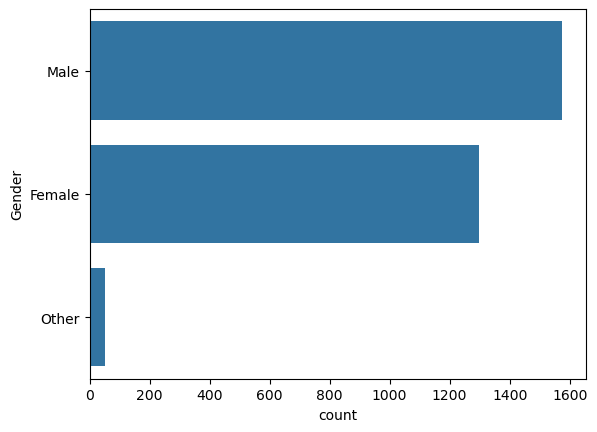

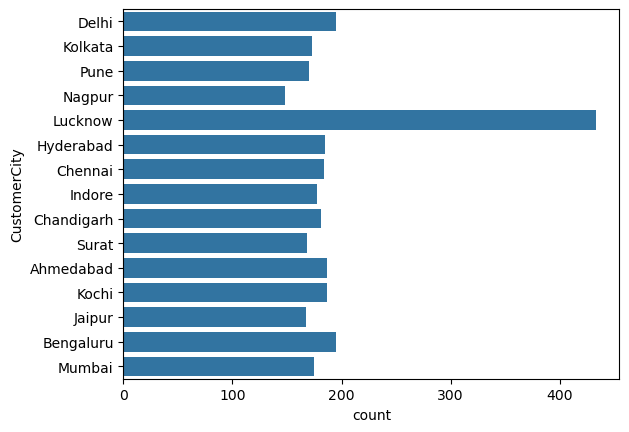

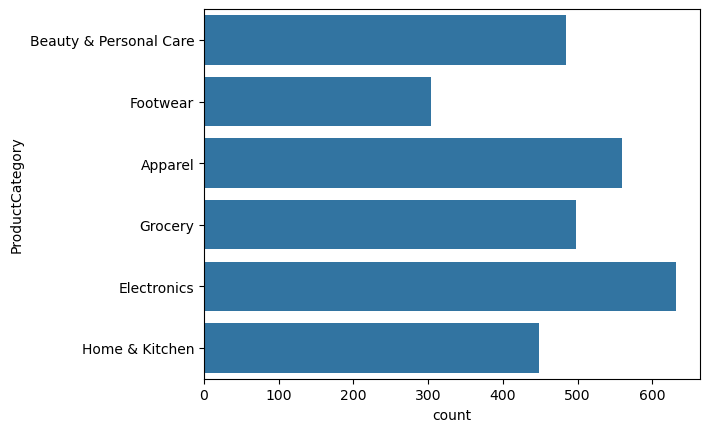

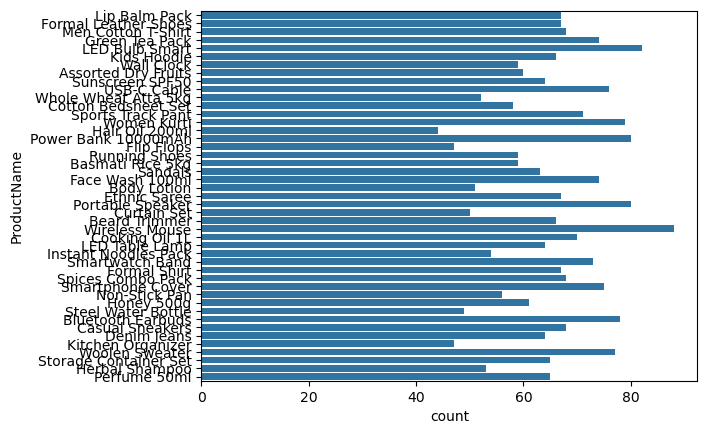

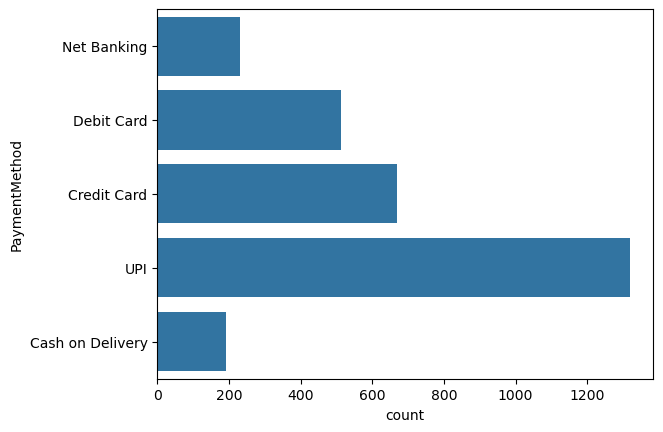

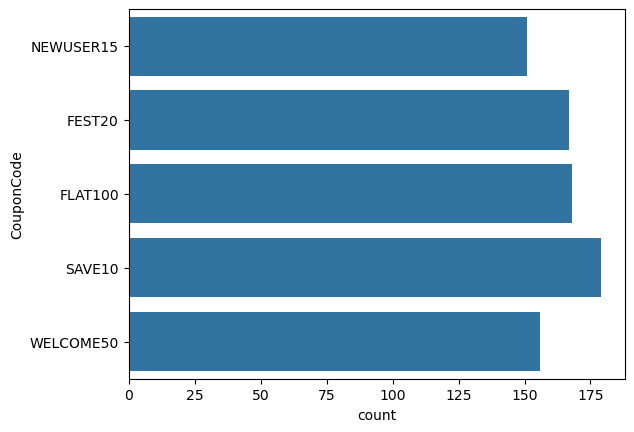

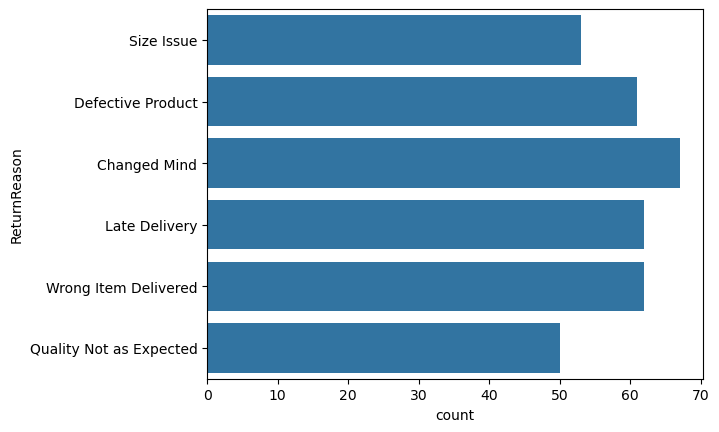

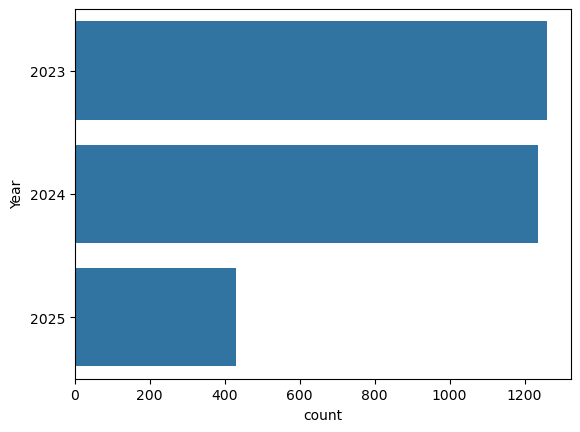

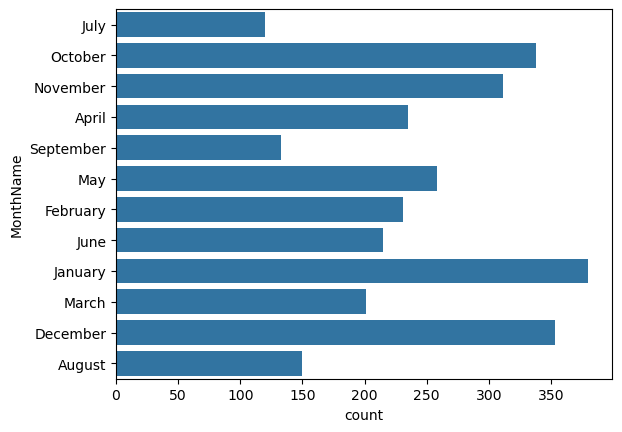

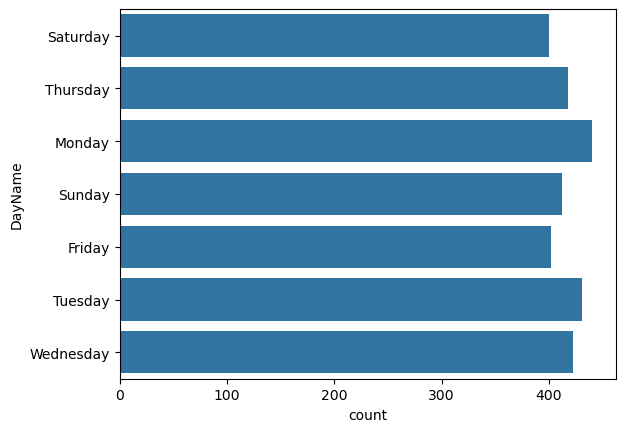

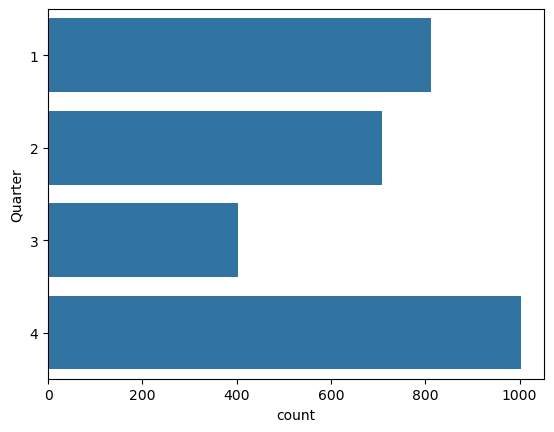

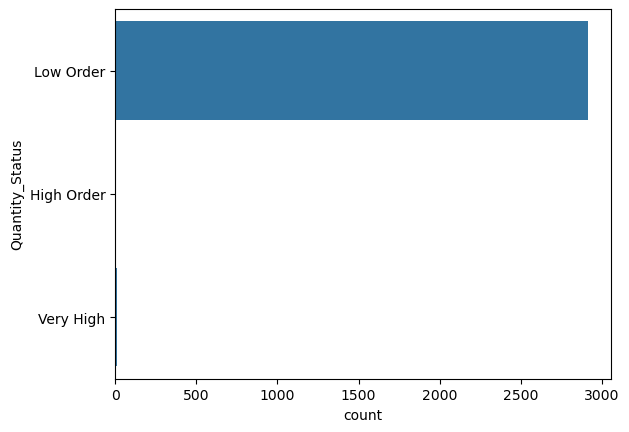

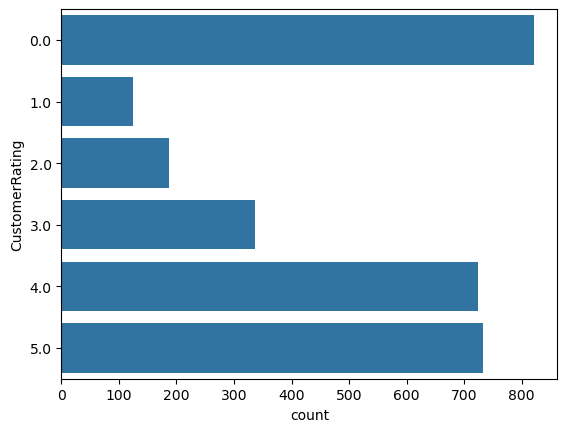

In [72]:
for i in univariate:
    sns.countplot(y = df[i])
    plt.show()                        #show first and then execute further 

In [73]:
#for float columns

In [74]:
numeric = df.select_dtypes(float).columns
numeric

Index(['CustomerAge', 'Quantity', 'UnitPrice', 'DiscountPercent',
       'DeliveryDays', 'CustomerRating', 'ShippingCost', 'Sales'],
      dtype='object')

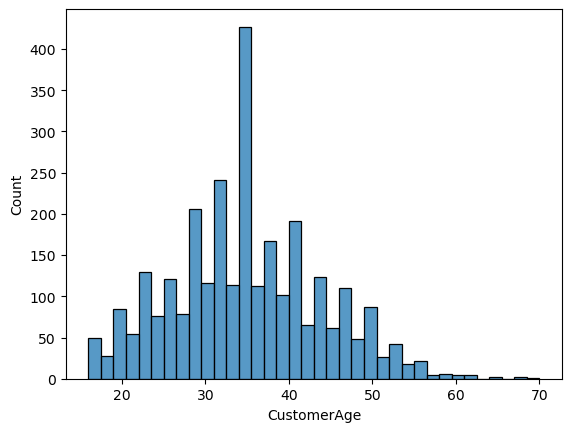

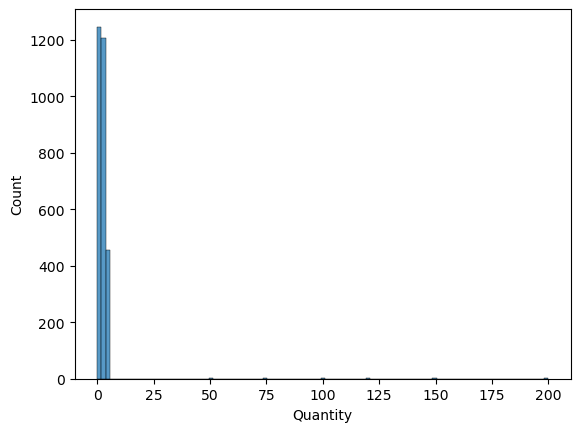

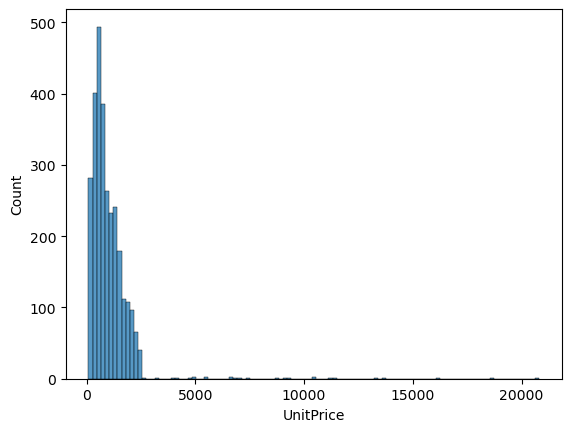

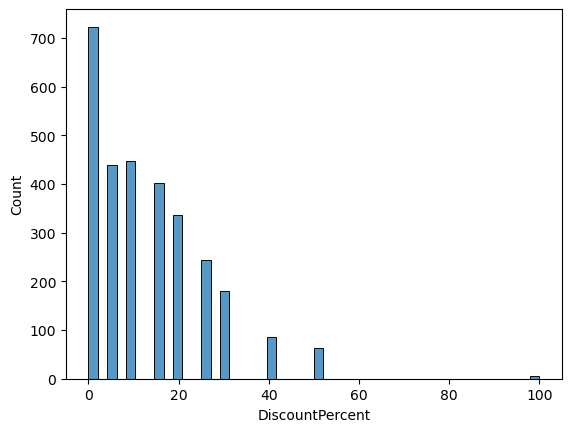

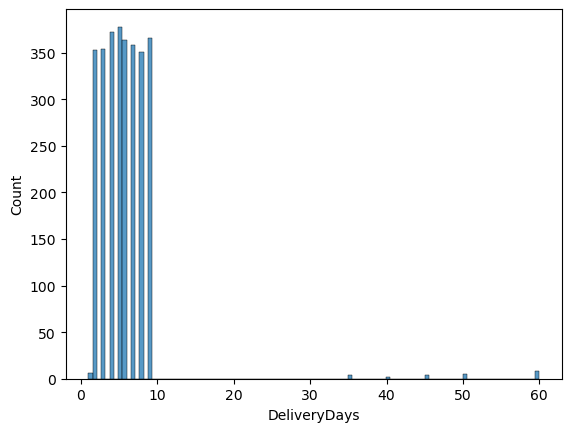

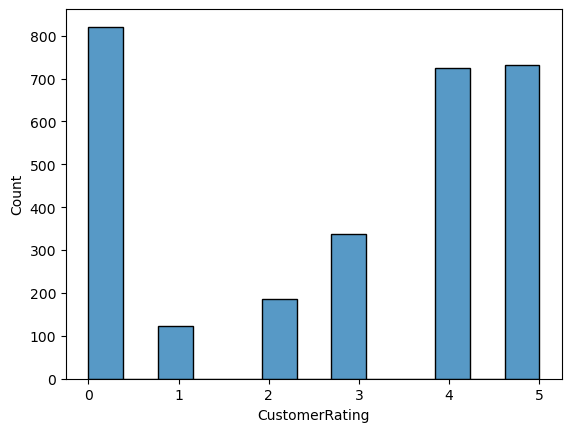

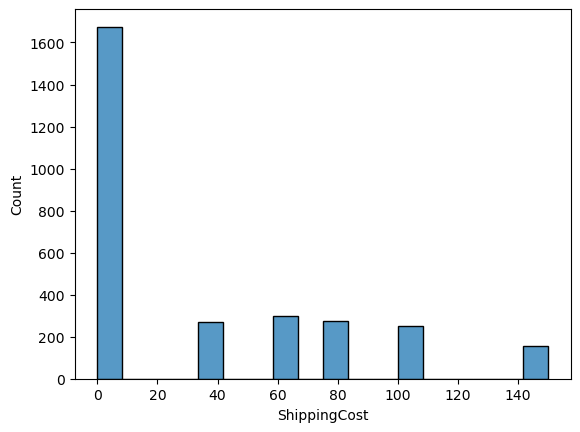

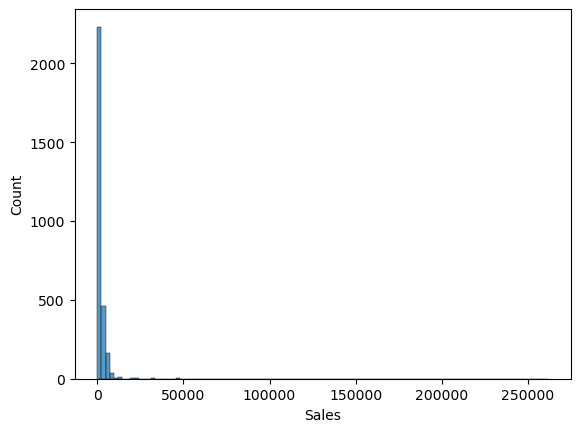

In [75]:
for i in numeric:
    sns.histplot(df[i])
    plt.show()

<Axes: ylabel='count'>

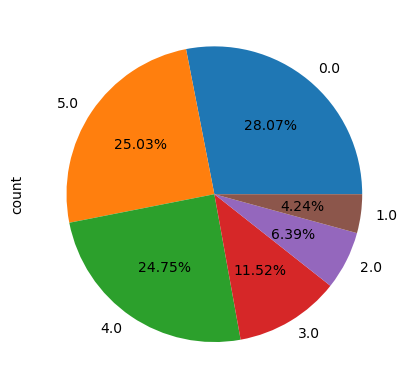

In [76]:
df['CustomerRating'].value_counts().plot(kind='pie',autopct='%0.02f%%')

# Bivariate Analysis

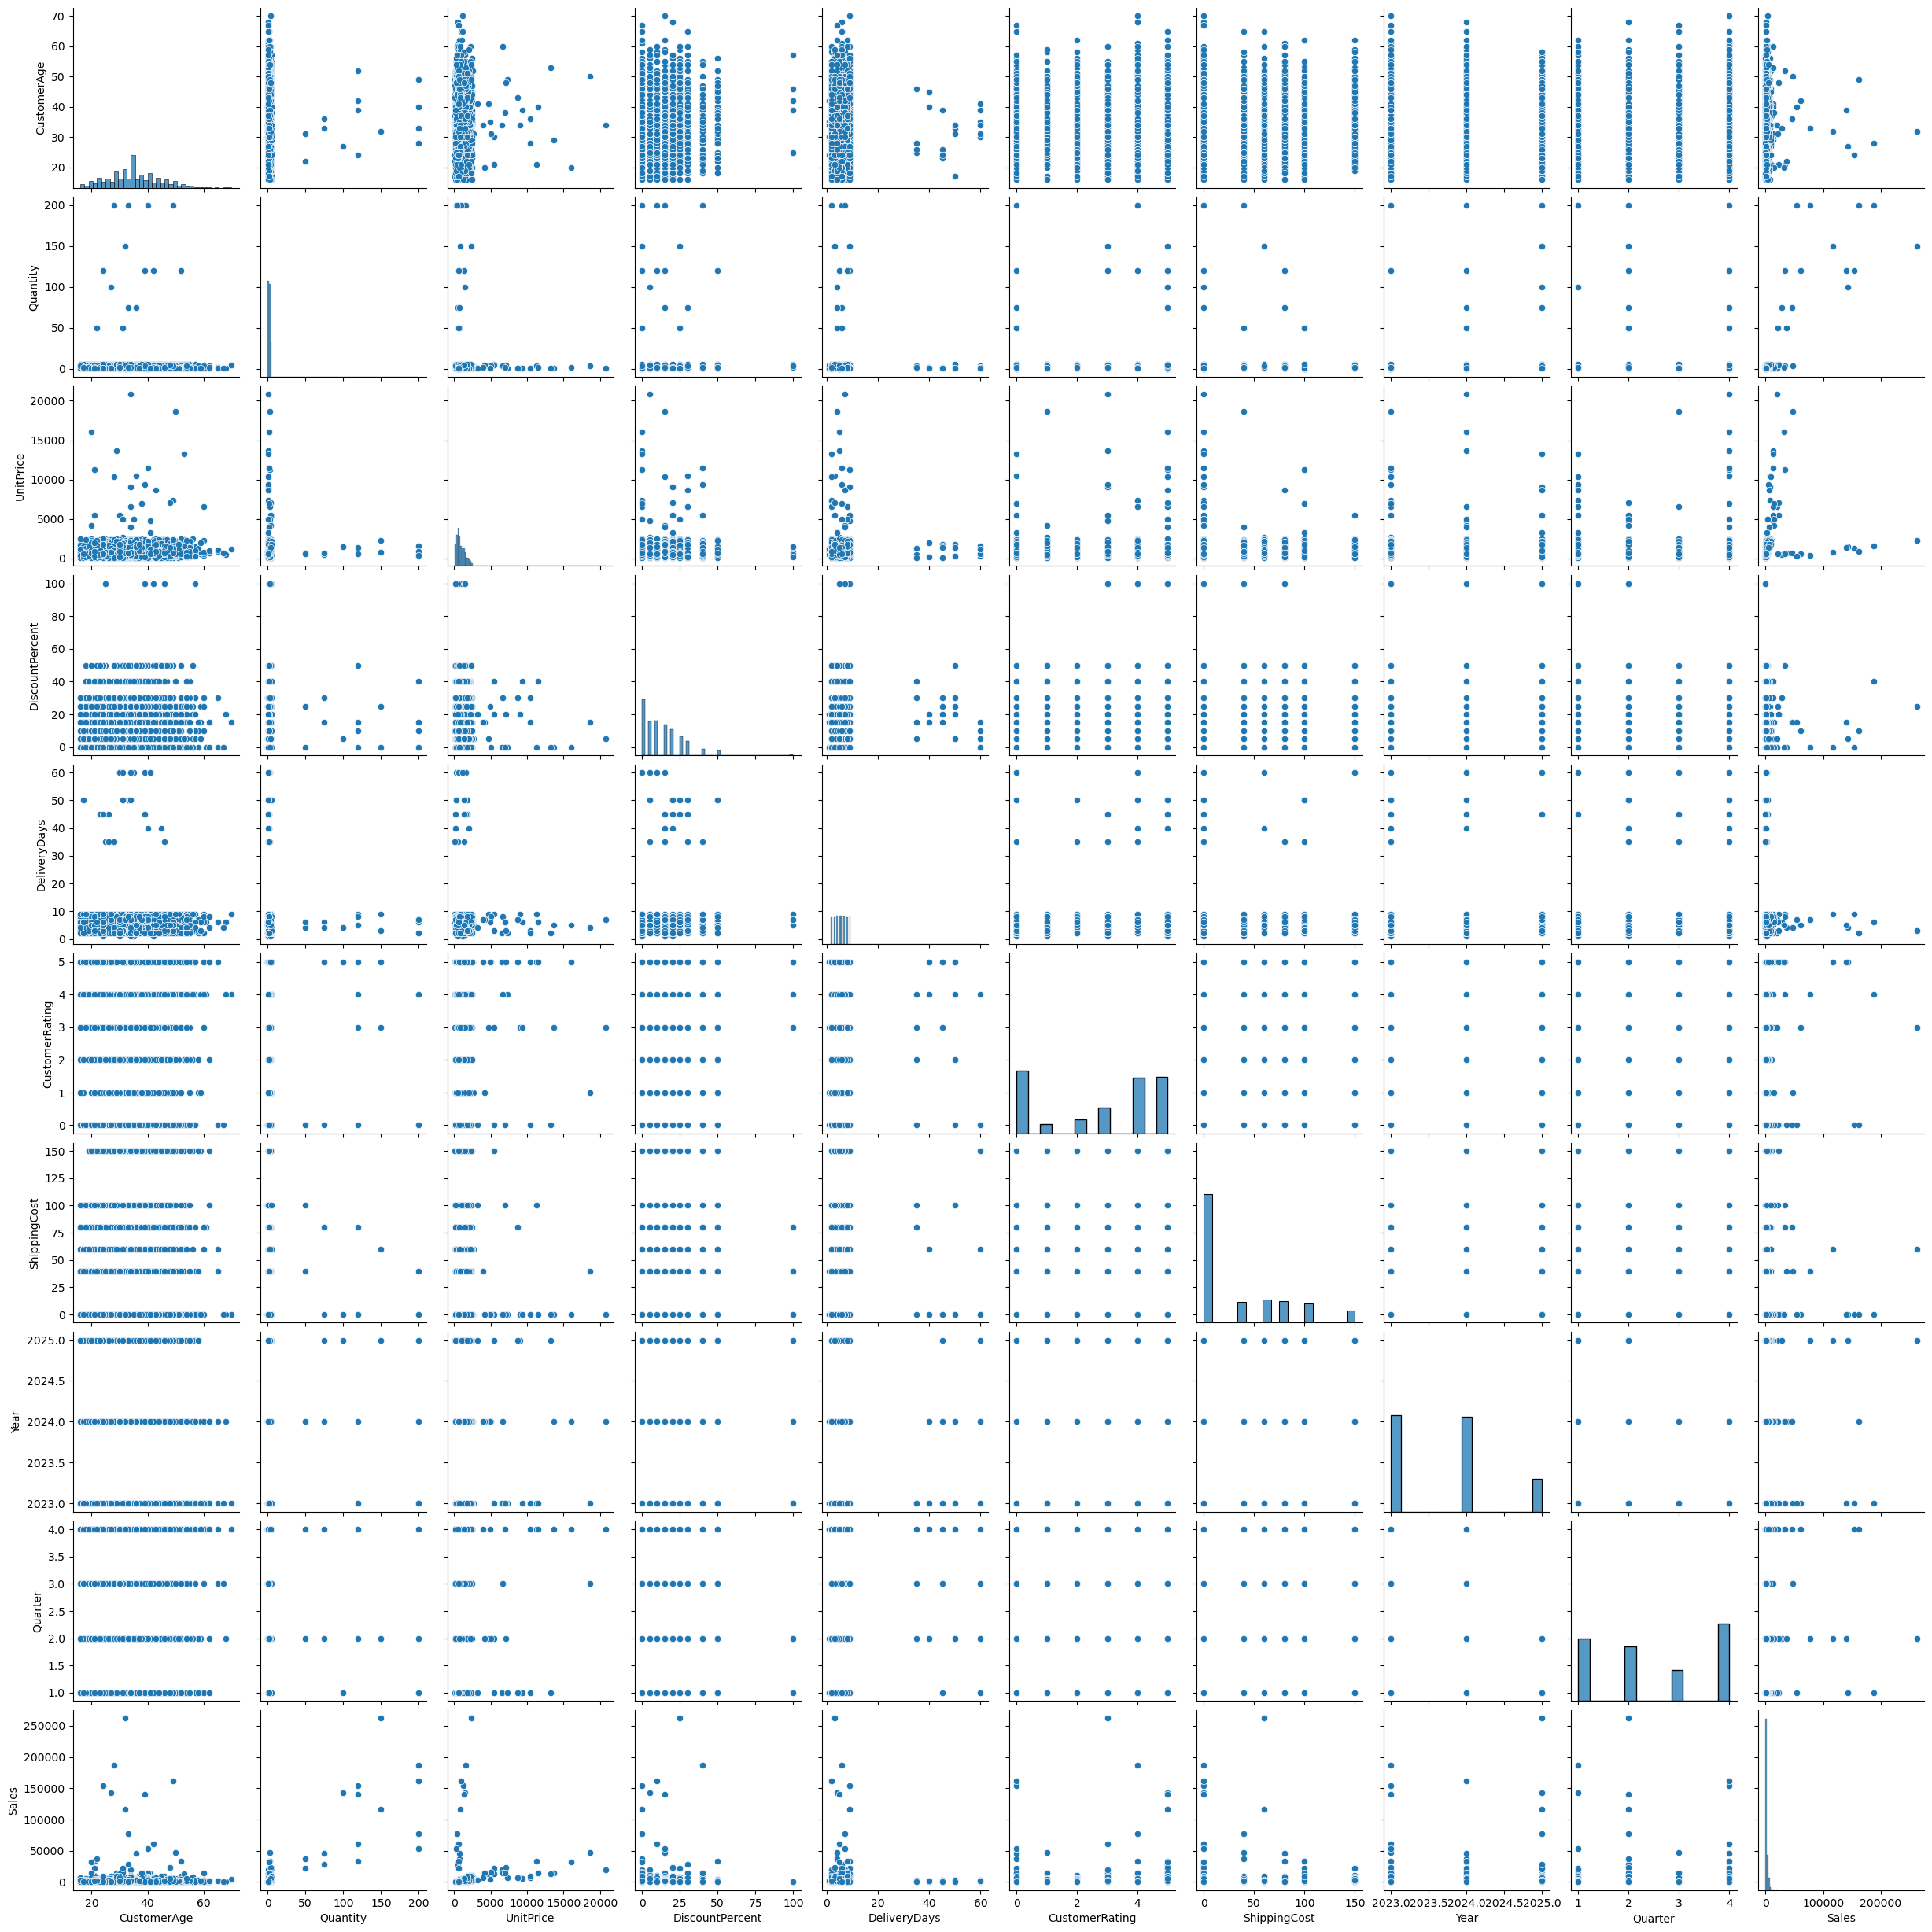

In [77]:
sns.pairplot(df)

<Axes: xlabel='Gender', ylabel='count'>

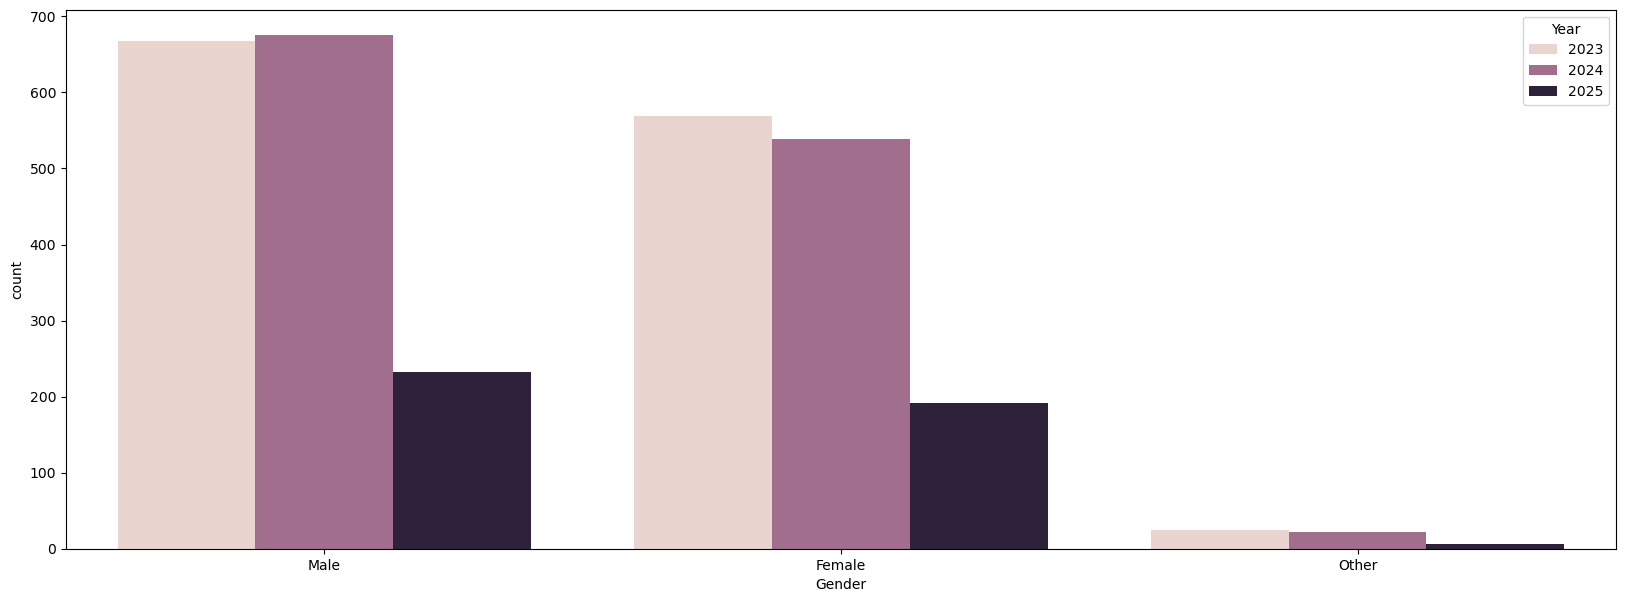

In [78]:
plt.figure(figsize=(20,7))
sns.countplot(x=df['Gender'],hue =df['Year'])

<Axes: xlabel='PaymentMethod', ylabel='count'>

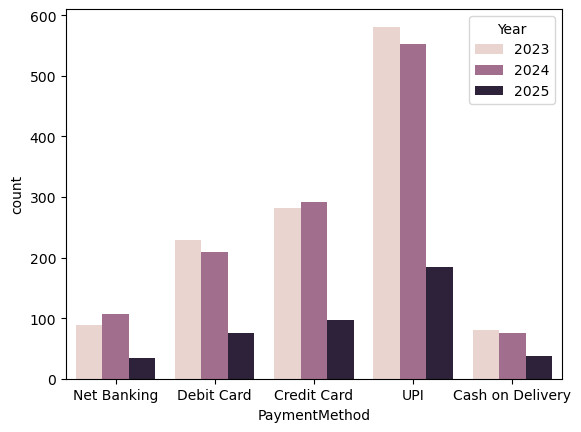

In [79]:
sns.countplot(x=df['PaymentMethod'],hue=df['Year'])

In [80]:
#In 2024, most of the payments were done by net banking
#In 2023, most of the payments were done by debit card,UPI,Cod

<Axes: xlabel='Gender', ylabel='count'>

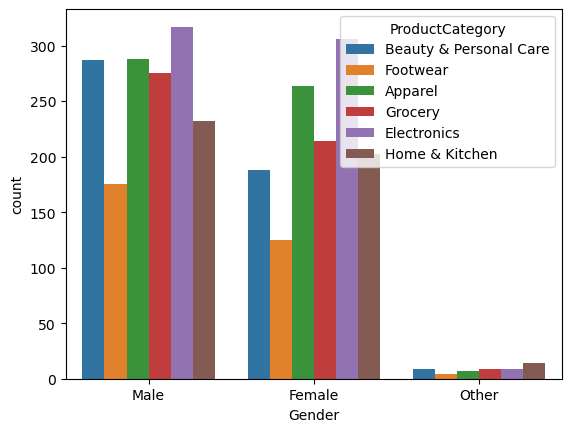

In [81]:
sns.countplot(x=df['Gender'],hue=df['ProductCategory'])

# Dealing with Outliers

In [82]:
df.describe()

,OrderDate,CustomerAge,Quantity,UnitPrice,DiscountPercent,DeliveryDays,CustomerRating,ShippingCost,Year,Quarter,Sales
count,2925,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000
mean,2024-03-20 20:16:59.076922880,34.609573,2.748376,997.884354,12.994872,5.837265,2.757265,33.856410,2023.715897,2.545299,2359.741422
min,2023-01-01 00:00:00,16.000000,0.000000,80.350000,0.000000,1.000000,0.000000,0.000000,2023.000000,1.000000,0.000000
25%,2023-09-22 00:00:00,29.000000,1.000000,478.610000,5.000000,4.000000,0.000000,0.000000,2023.000000,1.000000,644.592000
50%,2024-02-14 00:00:00,34.000000,2.000000,786.670000,10.000000,5.000000,3.000000,0.000000,2024.000000,2.000000,1236.720000
75%,2024-11-06 00:00:00,40.000000,3.000000,1328.540000,20.000000,8.000000,5.000000,60.000000,2024.000000,4.000000,2309.840000
max,2025-06-29 00:00:00,70.000000,200.000000,20819.867889,100.000000,60.000000,5.000000,150.000000,2025.000000,4.000000,261862.125000
std,NaN,8.952300,9.853663,1030.098789,12.356771,4.552346,1.987621,44.937636,0.704905,1.220163,8937.501977


In [83]:
num_cols = df.select_dtypes([int,float]).columns
num_cols

Index(['CustomerAge', 'Quantity', 'UnitPrice', 'DiscountPercent',
       'DeliveryDays', 'CustomerRating', 'ShippingCost', 'Year', 'Quarter',
       'Sales'],
      dtype='object')

In [84]:
df['CustomerAge'].quantile(0.25)


np.float64(29.0)

In [85]:
df['CustomerAge'].quantile(0.75)

np.float64(40.0)

In [86]:
for i in num_cols:
    q1= df[i].quantile(0.25)
    q3= df[i].quantile(0.75)
    iqr = q3 - q1
    lower = q1-1.5*iqr
    upper = q3+1.5*iqr
    df[i] = df[i].clip(lower,upper)

<Axes: >

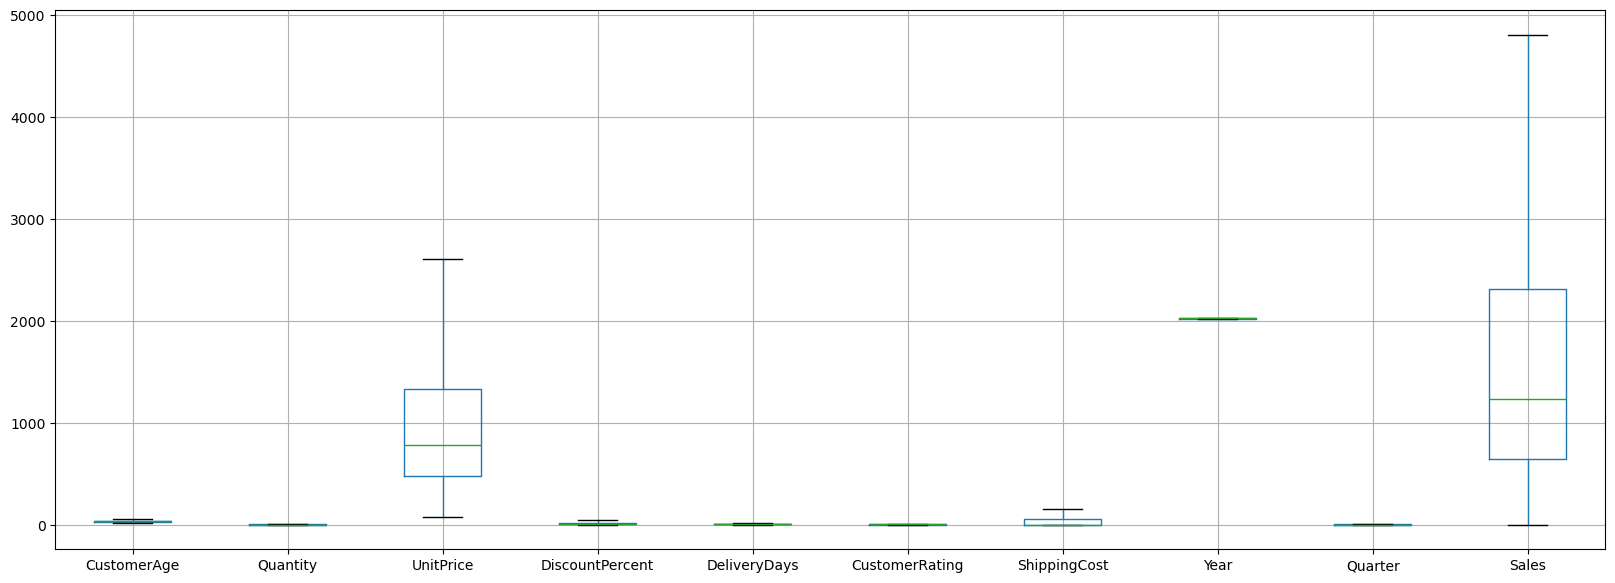

In [87]:
plt.figure(figsize=(20,7))
df.boxplot()

In [88]:
df.to_csv('cleaned_sales.csv',index= False)   #Saving cleaned dataset
